# 타겟 vs 피처: corr · mutual information

- 타겟 `y_h` = log(P_{t+h}/P_t) (기본 target `logdiff`), 피처 = `04_model_input/tabular.parquet` 의 모든 피처 열.
- `origin_start` **이전** 주만 사용 — 평가 구간을 피처 고르기에 쓰지 않는다.
- x = Pearson corr, y = MI. corr 은 0 근처인데 MI 가 높으면 비선형 관계 후보.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from sklearn.feature_selection import mutual_info_regression

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.utils import xy_columns

params = yaml.safe_load((ROOT / "conf/base/parameters.yml").read_text())
tab = pd.read_parquet(ROOT / "data/04_model_input/tabular.parquet")
tab = tab[tab.week < params["origin_start"]]
feats, ycols = xy_columns(tab, params["horizon"])

block = {}
for key, cols in json.loads((ROOT / "data/03_feature/feature_columns.json").read_text()).items():
    for c in cols:
        block[c] = key.split(":")[0] + ("_d" if "__d" in c else "")

HORIZONS = [1, 4, 8]
MIN_N = 52
print(tab.shape, len(feats), "features, weeks <", params["origin_start"])

(5265, 139) 127 features, weeks < 2024-01-01


In [2]:
rows = []
for s, g in tab.groupby("series"):
    for h in HORIZONS:
        y = g[f"y{h}"]
        for f in feats:
            ok = g[f].notna() & y.notna()
            if ok.sum() < MIN_N or g.loc[ok, f].nunique() < 2:
                continue
            x = g.loc[ok, f]
            mi = mutual_info_regression(x.to_frame(), y[ok], random_state=0)[0]
            rows.append((s, h, f, block.get(f, "?"), int(ok.sum()), x.corr(y[ok]), mi))
stats = pd.DataFrame(rows, columns=["series", "h", "feature", "block", "n", "corr", "mi"])
stats.groupby(["series", "h"]).size().unstack()

h,1,4,8
series,,,
coffee,61,61,61
copper,79,79,79
gold,69,69,69


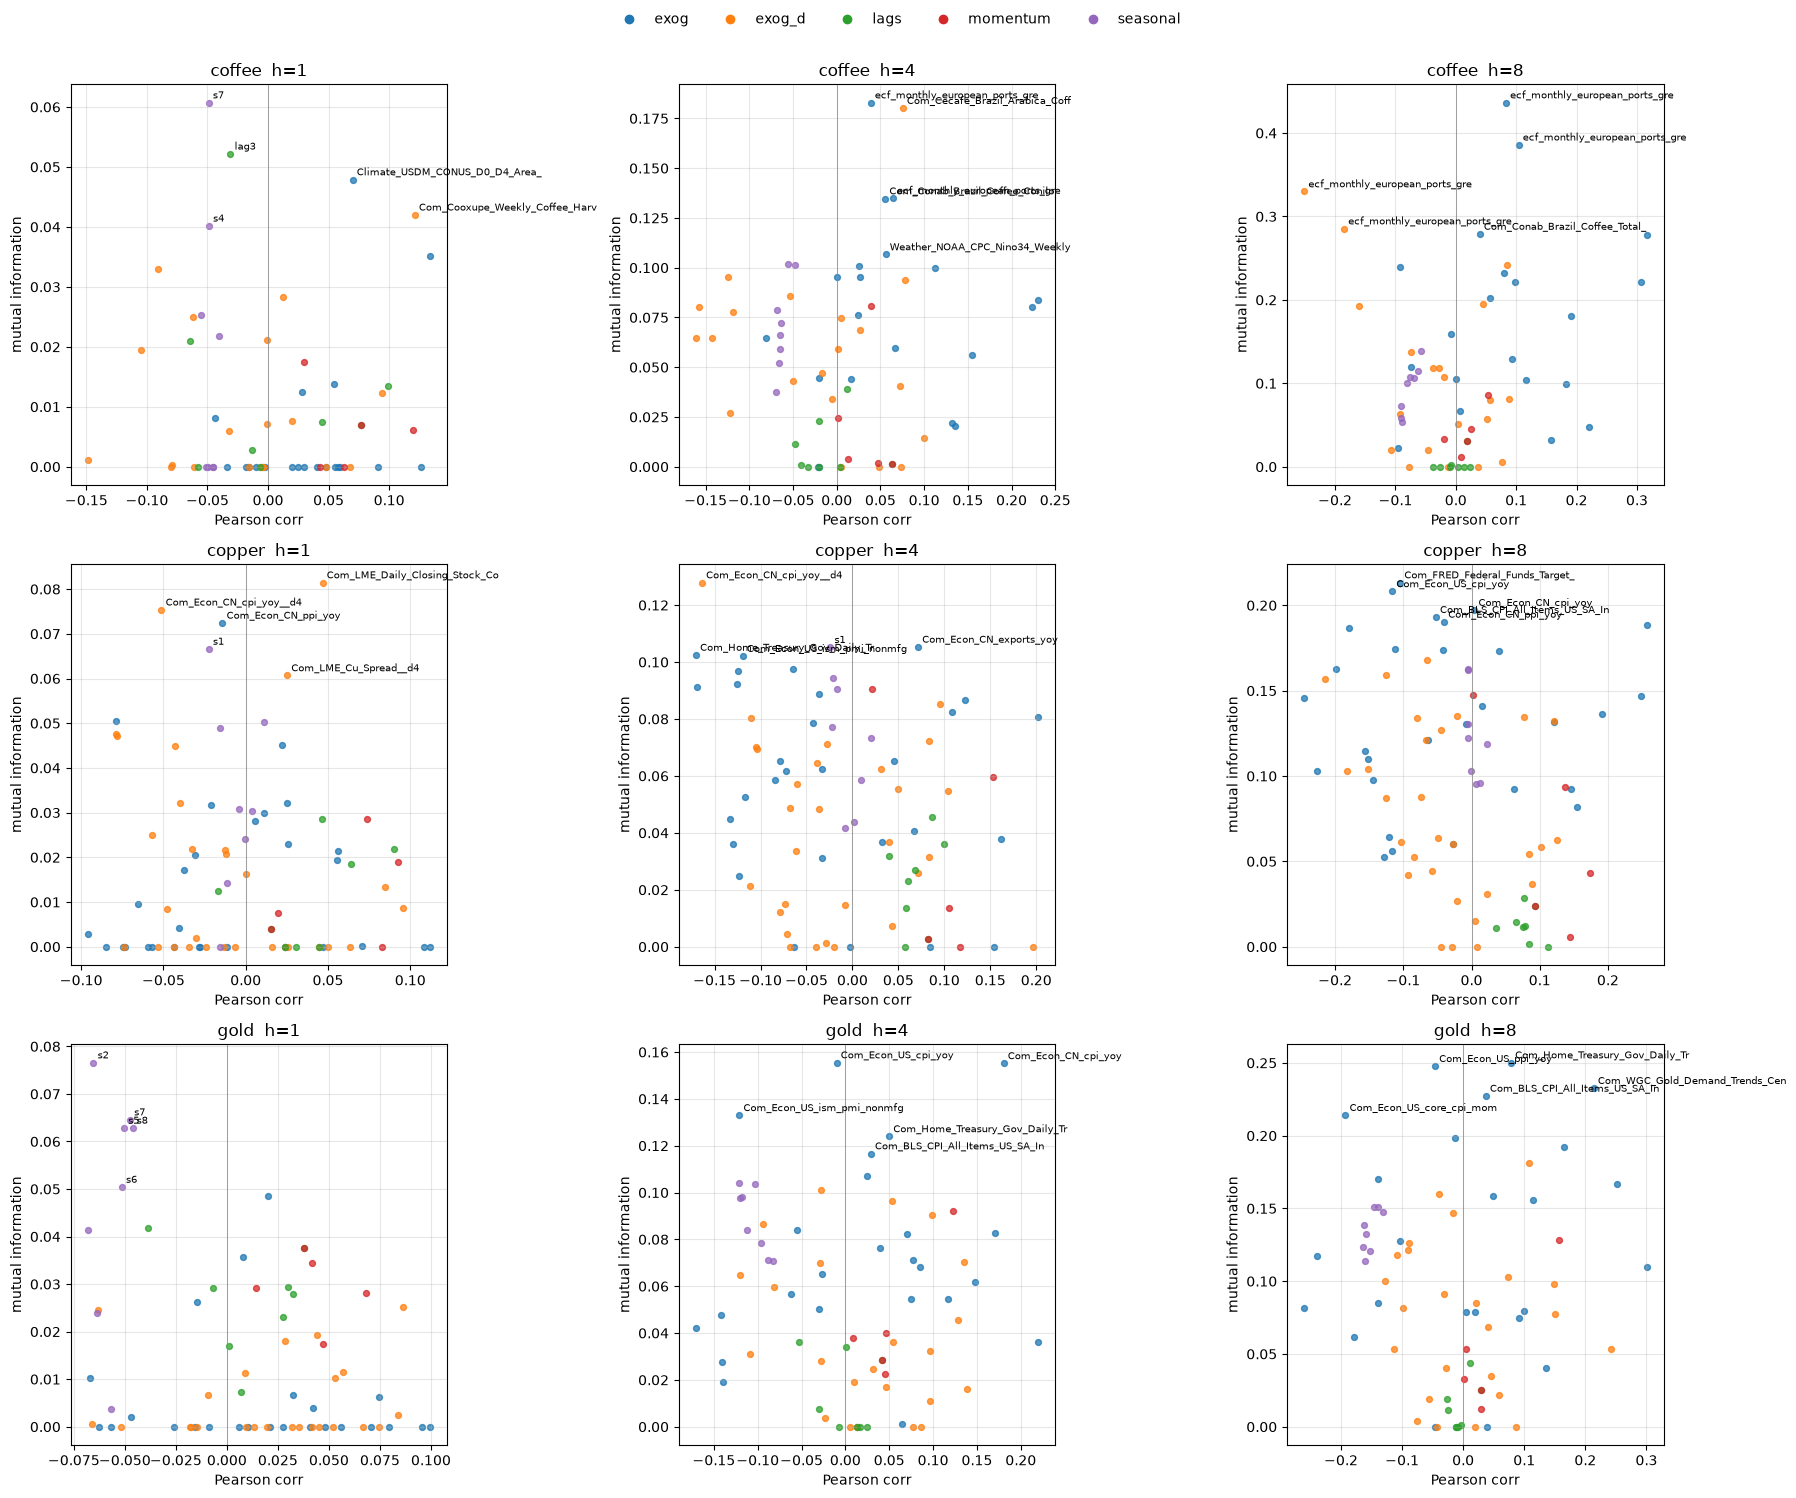

In [3]:
series = sorted(stats.series.unique())
blocks = sorted(stats.block.unique())
colors = dict(zip(blocks, plt.cm.tab10.colors))
fig, axes = plt.subplots(len(series), len(HORIZONS), figsize=(6 * len(HORIZONS), 5 * len(series)), squeeze=False)
for i, s in enumerate(series):
    for j, h in enumerate(HORIZONS):
        ax, d = axes[i, j], stats[(stats.series == s) & (stats.h == h)]
        for b, db in d.groupby("block"):
            ax.scatter(db["corr"], db["mi"], s=18, alpha=0.75, color=colors[b], label=b)
        for _, r in d.nlargest(5, "mi").iterrows():
            ax.annotate(r.feature[:30], (r["corr"], r.mi), fontsize=7, xytext=(3, 3), textcoords="offset points")
        ax.axvline(0, color="grey", lw=0.5)
        ax.set(title=f"{s}  h={h}", xlabel="Pearson corr", ylabel="mutual information")
        ax.grid(alpha=0.3)
handles = [plt.Line2D([], [], marker="o", ls="", color=colors[b], label=b) for b in blocks]
fig.legend(handles=handles, loc="upper center", ncol=len(blocks), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.97))

In [4]:
for s in series:
    print(f"\n== {s}  h=1  MI 상위 15 ==")
    d = stats[(stats.series == s) & (stats.h == 1)].nlargest(15, "mi")
    print(d[["feature", "block", "n", "corr", "mi"]].round(4).to_string(index=False))


== coffee  h=1  MI 상위 15 ==
                                                                  feature    block    n    corr     mi
                                                                       s7 seasonal 1099 -0.0490 0.0607
                                                                     lag3     lags 1139 -0.0310 0.0522
                                    Climate_USDM_CONUS_D0_D4_Area_Percent     exog  470  0.0698 0.0479
                       Com_Cooxupe_Weekly_Coffee_Harvest_Progress_Pct__d4   exog_d  122  0.1211 0.0420
                                                                       s4 seasonal 1096 -0.0488 0.0402
              Com_Cecafe_Brazil_Conillon_Coffee_Exports_Million_60kg_Bags     exog  412  0.1338 0.0351
          ecf_monthly_european_ports_green_coffee_stocks_total_tonnes__d4   exog_d  194 -0.0906 0.0330
                                               Com_EPU_Gpr_Daily_Gprd__d4   exog_d  466  0.0126 0.0282
                                            